# Exploratory data analysis

Campus Apartment Finder, Midwest scope. Listings are from 2018 and 2019, so every rent is a historical asking price.

This notebook follows section 3.3 of the project proposal: distributions and summary statistics for rent and square footage, a correlation matrix among the numeric predictors, scatterplots of rent against each continuous variable, boxplots of rent by bedroom count and by amenity presence, and outlier identification. It also covers the missing-data check from section 3.1.

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from src import model

sns.set_theme(style='whitegrid', rc={'axes.edgecolor': '#dddbd5', 'grid.color': '#e4e3df'})
plt.rcParams['text.parse_math'] = False
BLUE = '#2a78d6'
pd.set_option('display.float_format', lambda value: f'{value:,.2f}')

## Data

These are the cleaned Midwest listings that have price, bedrooms, bathrooms and square footage. Cleaning already converted weekly rents to monthly and removed rents outside $200 to $20,000, duplicates, reposts of the same unit, and listings whose body text contradicts their price. The engineered columns from section 3.2 (distance from campus, price per square foot, cost per bedroom, amenity count) are added here.

In [2]:
frame = model.load_midwest()
for amenity in ['Parking', 'Pool', 'Gym', 'Washer Dryer', 'Dishwasher', 'Patio/Deck', 'AC', 'Storage']:
    frame[f'has_{amenity}'] = frame['amenity_list'].map(lambda items, name=amenity: None if items is None else name in items)
print(f'{len(frame):,} listings, {frame.state.nunique()} states, {int(frame.is_chicago_metro.sum()):,} in the Chicago metro')
frame.groupby('state').size().sort_values(ascending=False).rename('listings').to_frame().T

11,977 listings, 12 states, 721 in the Chicago metro


state,OH,MO,IL,NE,KS,ND,MI,MN,IN,WI,IA,SD
listings,4632,1172,1018,983,819,726,689,572,496,417,367,86


## Missing data

The proposal planned to test whether missing square footage is missing at random. Square footage turns out to be complete, so no imputation is needed. The fields that are missing are pet policy and amenities, and the app treats both as unknown rather than as no.

In [3]:
raw = pd.read_csv(model.SLIM_FILE, low_memory=False)
raw = raw[raw.state.isin(model.MIDWEST_STATES)]
share = raw.isna().mean().mul(100).sort_values(ascending=False)
share[share > 0].rename('percent missing').to_frame()

,percent missing
pets_allowed,50.57
amenities,18.87
bathrooms,0.11
bedrooms,0.10


In [4]:
frame.assign(pets_stated=frame.pets_allowed.notna()).groupby('pets_stated')[['price', 'square_feet', 'bedrooms']].median()

,price,square_feet,bedrooms
pets_stated,,,
False,985.00,918.00,2.00
True,970.00,851.00,2.00


## Distributions and summary statistics

In [5]:
frame[['price', 'square_feet', 'bedrooms', 'bathrooms', 'distance_from_campus_miles', 'amenity_count', 'price_per_sqft', 'cost_per_bedroom']].describe().T

,count,mean,std,min,25%,50%,75%,max
price,"11,977.00","1,116.19",546.25,224.00,775.00,975.00,"1,325.00","15,000.00"
square_feet,"11,977.00",948.40,395.39,200.00,715.00,890.00,"1,105.00","12,000.00"
bedrooms,"11,977.00",1.78,0.78,0.00,1.00,2.00,2.00,9.00
bathrooms,"11,977.00",1.38,0.54,1.00,1.00,1.00,2.00,7.00
distance_from_campus_miles,"11,977.00",306.90,150.87,0.72,246.27,293.98,388.45,890.97
amenity_count,"9,721.00",4.03,2.75,1.00,2.00,3.00,5.00,17.00
price_per_sqft,"11,977.00",1.24,0.54,0.05,0.90,1.09,1.41,9.40
cost_per_bedroom,"11,977.00",707.37,385.20,133.33,437.50,615.00,862.50,"4,000.00"


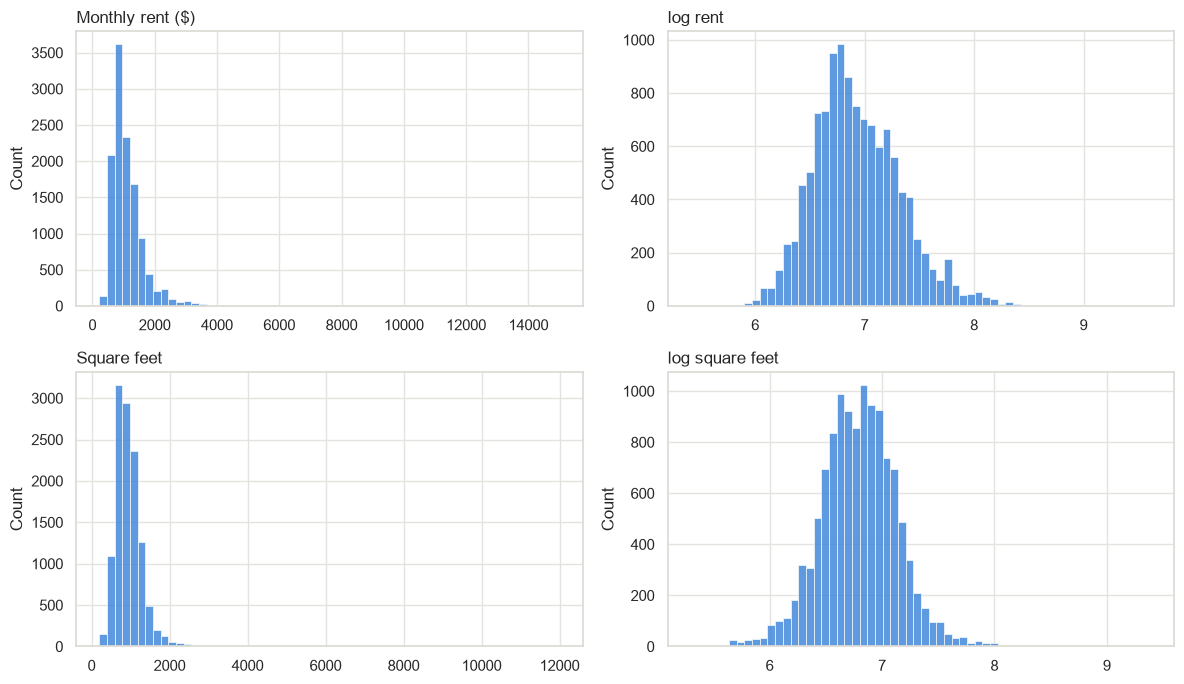

In [6]:
figure, axes = plt.subplots(2, 2, figsize=(12, 7))
sns.histplot(frame.price, bins=60, color=BLUE, ax=axes[0, 0]).set_title('Monthly rent ($)', loc='left')
sns.histplot(np.log(frame.price), bins=60, color=BLUE, ax=axes[0, 1]).set_title('log rent', loc='left')
sns.histplot(frame.square_feet, bins=60, color=BLUE, ax=axes[1, 0]).set_title('Square feet', loc='left')
sns.histplot(np.log(frame.square_feet), bins=60, color=BLUE, ax=axes[1, 1]).set_title('log square feet', loc='left')
for axis in axes.flat:
    axis.set_xlabel('')
plt.tight_layout()

In [7]:
pd.DataFrame(model.skew_report(frame)).T

,raw_skew,log_skew,use_log,transform
price,3.76,0.55,True,log
square_feet,5.30,0.23,True,log
distance_from_campus_miles,0.67,-2.22,False,log1p


## Correlation matrix

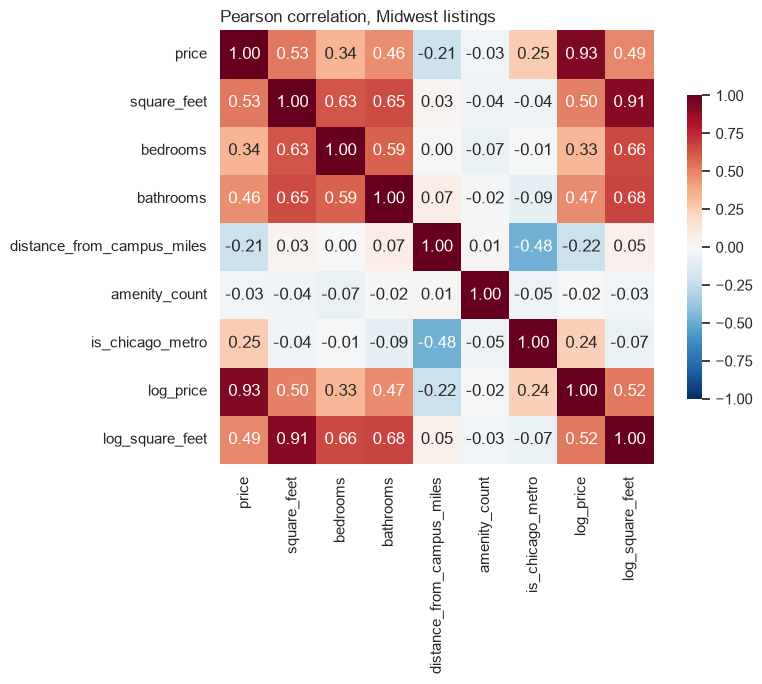

In [8]:
numeric = frame[['price', 'square_feet', 'bedrooms', 'bathrooms', 'distance_from_campus_miles', 'amenity_count', 'is_chicago_metro']].assign(log_price=np.log(frame.price), log_square_feet=np.log(frame.square_feet))
correlation = numeric.corr()
plt.figure(figsize=(9, 7))
sns.heatmap(correlation, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, square=True, cbar_kws={'shrink': 0.7})
plt.title('Pearson correlation, Midwest listings', loc='left')
plt.tight_layout()

### Collinearity among predictors

The variance inflation factor (VIF) measures how well each predictor is explained by the others. Values above about 5 signal collinearity that makes individual linear coefficients unstable.

In [9]:
predictors = numeric[['log_square_feet', 'bedrooms', 'bathrooms', 'distance_from_campus_miles']].assign(amenity_count=frame.amenity_count.fillna(0)).dropna()
vif = {}
for column in predictors.columns:
    others = predictors.drop(columns=column)
    r_squared = LinearRegression().fit(others, predictors[column]).score(others, predictors[column])
    vif[column] = 1 / (1 - r_squared)
pd.Series(vif, name='VIF').to_frame()

,VIF
log_square_feet,2.28
bedrooms,1.90
bathrooms,2.00
distance_from_campus_miles,1.01
amenity_count,1.01


## Rent against each continuous variable

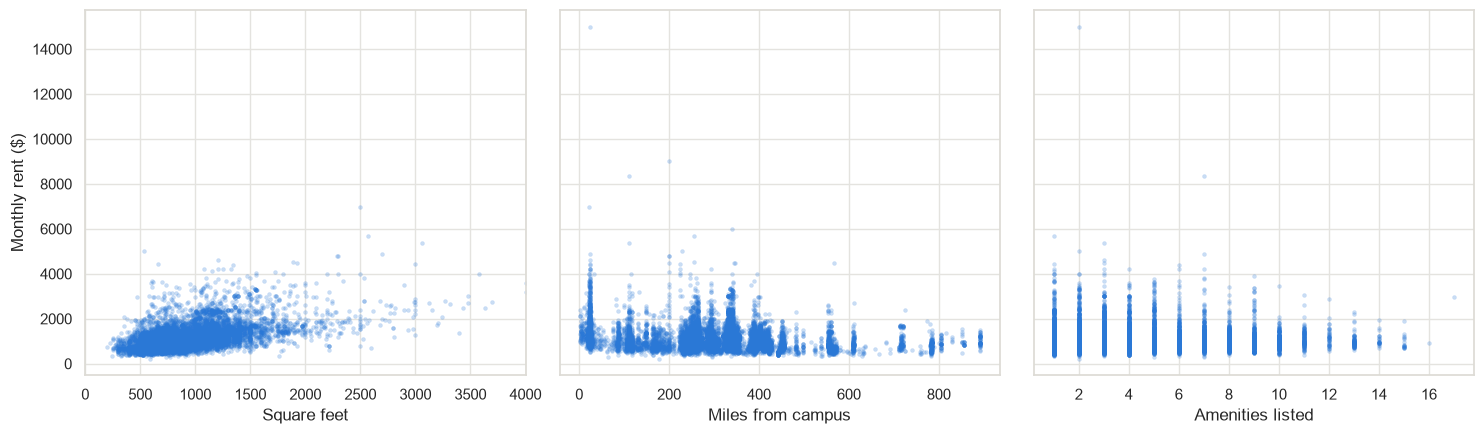

In [10]:
figure, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for axis, column, label in zip(axes, ['square_feet', 'distance_from_campus_miles', 'amenity_count'], ['Square feet', 'Miles from campus', 'Amenities listed']):
    sns.scatterplot(data=frame, x=column, y='price', s=8, alpha=0.25, color=BLUE, edgecolor=None, ax=axis)
    axis.set_xlabel(label)
    axis.set_ylabel('Monthly rent ($)')
axes[0].set_xlim(0, 4000)
plt.tight_layout()

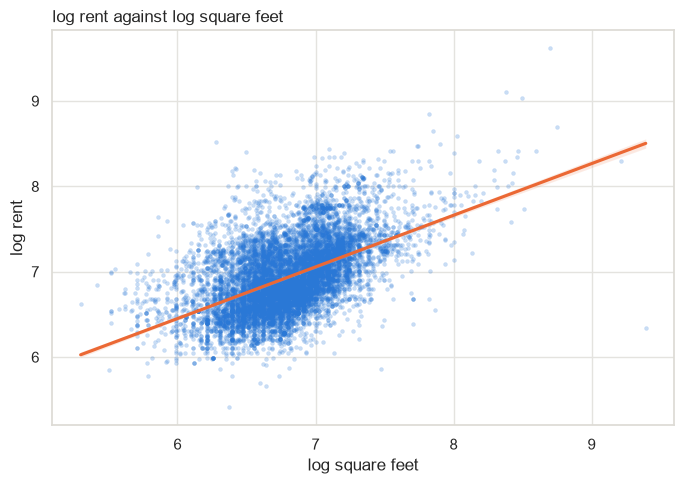

In [11]:
plt.figure(figsize=(7, 5))
sns.scatterplot(x=np.log(frame.square_feet), y=np.log(frame.price), s=8, alpha=0.25, color=BLUE, edgecolor=None)
sns.regplot(x=np.log(frame.square_feet), y=np.log(frame.price), scatter=False, color='#eb6834')
plt.xlabel('log square feet')
plt.ylabel('log rent')
plt.title('log rent against log square feet', loc='left')
plt.tight_layout()

## Rent by bedroom count and by amenity presence

,count,25%,50%,75%
bedroom_group,,,,
1,"4,516.00",705.00,879.00,"1,175.00"
2,"5,733.00",795.00,985.00,"1,310.00"
3,"1,328.00",975.00,"1,250.00","1,557.00"
4+,314.00,"1,400.00","1,800.00","2,500.00"
Studio,86.00,596.25,775.00,"1,054.25"


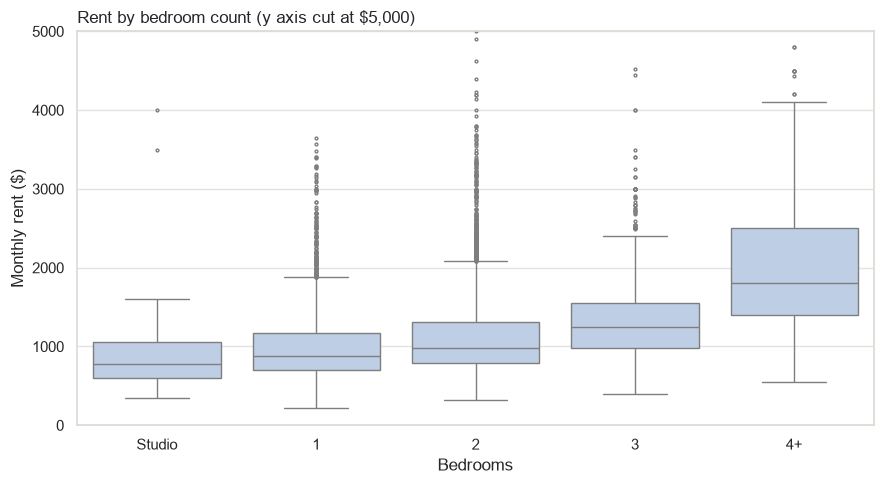

In [12]:
bedrooms = frame.assign(bedroom_group=frame.bedrooms.clip(upper=4).map({0: 'Studio', 1: '1', 2: '2', 3: '3', 4: '4+'}))
plt.figure(figsize=(9, 5))
sns.boxplot(data=bedrooms, x='bedroom_group', y='price', order=['Studio', '1', '2', '3', '4+'], color='#b7cdec', fliersize=2)
plt.ylim(0, 5000)
plt.xlabel('Bedrooms')
plt.ylabel('Monthly rent ($)')
plt.title('Rent by bedroom count (y axis cut at $5,000)', loc='left')
plt.tight_layout()
bedrooms.groupby('bedroom_group').price.describe()[['count', '25%', '50%', '75%']]

present,Listed,Not listed
amenity,,
AC,850.00,995.00
Dishwasher,935.00,990.00
Gym,"1,044.00",935.00
Parking,"1,010.00",910.00
Patio/Deck,960.00,985.00
Pool,984.00,965.00
Storage,986.00,965.00
Washer Dryer,972.00,975.00


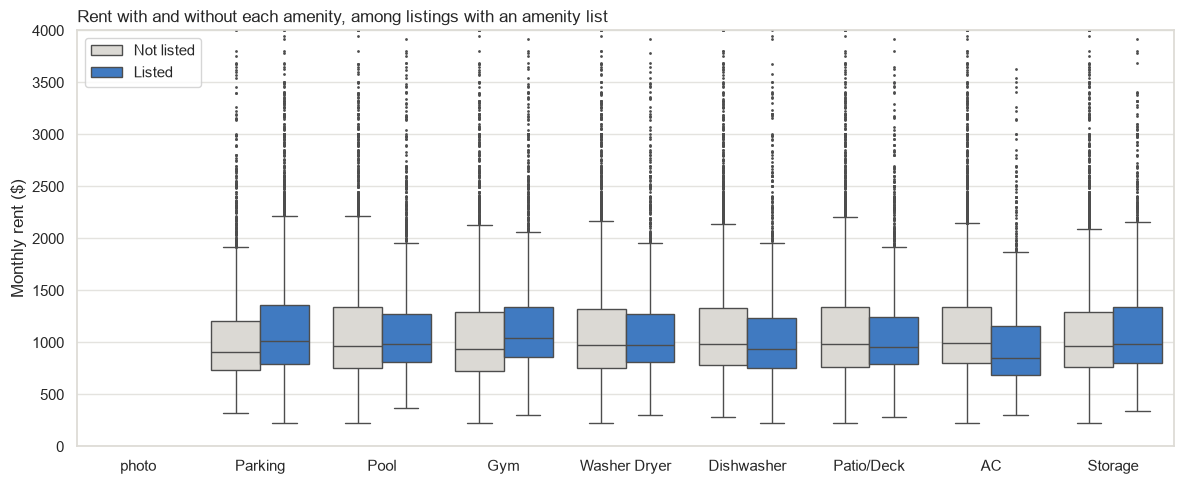

In [13]:
amenity_columns = [column for column in frame.columns if column.startswith('has_')]
long = frame.loc[frame.amenity_list.notna(), ['price', *amenity_columns]].melt(id_vars='price', var_name='amenity', value_name='present')
long['amenity'] = long['amenity'].str.replace('has_', '', regex=False)
long['present'] = long['present'].map({True: 'Listed', False: 'Not listed'})
plt.figure(figsize=(12, 5))
sns.boxplot(data=long, x='amenity', y='price', hue='present', hue_order=['Not listed', 'Listed'], palette=['#dcdad3', BLUE], fliersize=1)
plt.ylim(0, 4000)
plt.xlabel('')
plt.ylabel('Monthly rent ($)')
plt.title('Rent with and without each amenity, among listings with an amenity list', loc='left')
plt.legend(title='')
plt.tight_layout()
long.groupby(['amenity', 'present']).price.median().unstack()

## Outliers

Rent depends on size, so outliers are judged within bedroom count using the 1.5 x IQR rule on log rent. Outliers are reported and flagged, not deleted. Only rents outside $200 to $20,000 were removed in cleaning, following the proposal.

In [14]:
log_price = np.log(frame.price)
groups = frame.bedrooms.clip(upper=4)
quartiles = log_price.groupby(groups).quantile([0.25, 0.75]).unstack()
spread = quartiles[0.75] - quartiles[0.25]
lower = groups.map(quartiles[0.25] - 1.5 * spread)
upper = groups.map(quartiles[0.75] + 1.5 * spread)
outlier = (log_price < lower) | (log_price > upper)
print(f'{int(outlier.sum()):,} listings ({outlier.mean():.1%}) are rent outliers for their bedroom count')
print(f'{int((log_price > upper).sum()):,} high, {int((log_price < lower).sum()):,} low')
print(f'{int(frame.flagged.sum()):,} listings carry a cleaning flag')
frame.loc[outlier, ['cityname', 'state', 'price', 'bedrooms', 'bathrooms', 'square_feet', 'flagged']].sort_values('price', ascending=False).head(10)

154 listings (1.3%) are rent outliers for their bedroom count
141 high, 13 low
466 listings carry a cleaning flag


,cityname,state,price,bedrooms,bathrooms,square_feet,flagged
9957,Chicago,IL,"15,000.00",4.00,4.00,6000,False
118,Bloomington,IN,"9,000.00",7.00,7.00,4355,False
175,Madison,WI,"8,345.00",8.00,4.00,4900,False
1998,Chicago,IL,"6,995.00",3.00,3.00,2500,False
2116,Edina,MN,"6,000.00",5.00,4.00,6300,False
4856,Toledo,OH,"5,000.00",2.00,1.00,532,False
9720,Chicago,IL,"4,900.00",2.00,2.50,2700,False
10405,Chicago,IL,"4,625.00",2.00,2.00,1210,False
38,Birmingham,MI,"4,525.00",3.00,2.50,1884,False
10059,Chicago,IL,"4,450.00",3.00,2.00,662,False


In [15]:
frame.loc[outlier, 'state'].value_counts().head(8).rename('outliers').to_frame().join(frame.state.value_counts().rename('listings')).assign(share=lambda table: table.outliers / table.listings)

,outliers,listings,share
state,,,
IL,74,1018,0.07
OH,41,4632,0.01
MN,14,572,0.02
MI,9,689,0.01
MO,6,1172,0.01
KS,4,819,0.00
IN,3,496,0.01
WI,2,417,0.00


## Chicago metro against the rest of the Midwest

The proposal planned a single metro area. The Chicago metro has only about 700 usable listings, which is too few to model alone, so the model is trained on the Midwest with state and a Chicago indicator. This plot shows why the indicator matters.

,price,price_per_sqft,cost_per_bedroom,square_feet
area,,,,
Chicago metro,"1,417.00",1.88,908.33,800.00
Rest of Midwest,955.00,1.07,600.00,898.00


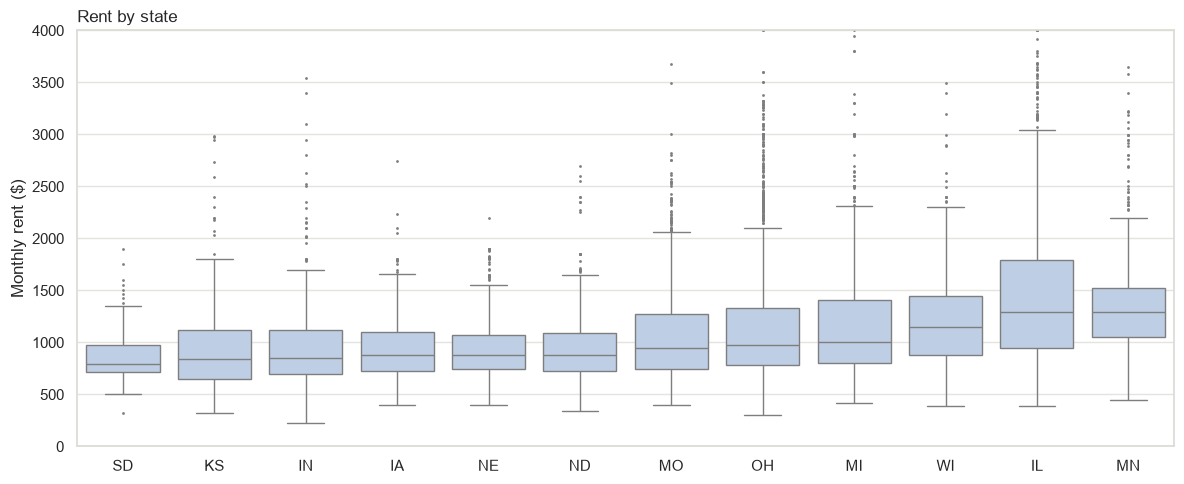

In [16]:
plt.figure(figsize=(12, 5))
order = frame.groupby('state').price.median().sort_values().index
sns.boxplot(data=frame, x='state', y='price', order=order, color='#b7cdec', fliersize=1)
plt.ylim(0, 4000)
plt.xlabel('')
plt.ylabel('Monthly rent ($)')
plt.title('Rent by state', loc='left')
plt.tight_layout()
frame.assign(area=np.where(frame.is_chicago_metro.eq(1), 'Chicago metro', 'Rest of Midwest')).groupby('area')[['price', 'price_per_sqft', 'cost_per_bedroom', 'square_feet']].median()

## Findings

- **Coverage.** There are 11,977 usable Midwest listings. Ohio dominates with 4,632 (39%), and Illinois has 1,018, of which 721 are in the Chicago metro.
- **Missing data.**
  - Square footage is complete, so the missing-at-random test planned in the proposal was not needed.
  - Pet policy is missing on 50.6% of listings and amenities on 18.9%.
  - Listings without a stated pet policy have nearly the same median rent ($985) as those with one ($970). Missingness does not look tied to price, which supports scoring it as unknown rather than as a negative.
- **Skew.** Rent (skew 3.76) and square footage (5.30) are strongly right-skewed. Logs bring them to 0.55 and 0.23, and log rent against log size is close to linear, so the model uses both on the log scale. Distance is left as is, because logging made its skew worse.
- **Collinearity.** Every VIF among the numeric predictors is below 2.3. Size, bedrooms and bathrooms are correlated but not enough to destabilise the linear coefficients.
- **Bedrooms.** Median rent climbs from $775 for studios to $879 for one bedroom, $985 for two, $1,250 for three and $1,800 for four or more.
- **Amenities.**
  - Listings that mention a gym or parking have higher median rents, by $109 and $100 respectively.
  - Listings that mention AC have a lower one, by $145. That reflects which kinds of buildings advertise AC, not the value of AC.
- **Outliers.**
  - 154 listings (1.3%) are rent outliers for their bedroom count, 141 of them high.
  - Illinois has a 7% outlier share against 2% or less elsewhere, driven by high-end Chicago units.
  - They are kept and visible, not deleted.
- **Chicago.** The Chicago metro's median rent is $1,417 against $955 for the rest of the Midwest, and $1.88 per square foot against $1.07. That gap is why the model needs a Chicago indicator, and why Midwest-wide estimates are least reliable there.
